# Import Modules

In [ ]:
%pip install ucimlrepo

# Data Processing
import numpy as np
import pandas as pd

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Data Transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Calibration
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import CalibrationDisplay
from sklearn.frozen import FrozenEstimator

# Model Evaluation
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import brier_score_loss, log_loss
from scipy.special import expit
from sklearn.base import clone

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Data Source
from ucimlrepo import fetch_ucirepo

To ensure our experiment is reproducible, we will set a single seed (42) to be used throughout the preliminary exploratory analysis.

In [ ]:
SEED = 42

We will also set multiple seeds for repeatedly conducting outer-splits

In [ ]:
OUTER_SEEDS = tuple(range(2007, 2027))

Missing a spam email (**False Negative - FN**) is generally not as costly as missing a real, potentially critical email (**False Positive - FP**). Consequently, we set the cost of a false positive to be significantly higher than a false negative ($C_{FP} > C_{FN}$).

In [ ]:
# Fixed parameters
N_DRAWS = 50
C_FPS = (1, 5, 20)
C_FN = 1
CALIBRATION_DRAWS = (100, 250, 500, 1000)

# Part 1: Spambase

The dataset was loaded from the UCI repository as a feature table plus a target column. From [UCI](#https://archive.ics.uci.edu/dataset/94/spambase), Spambase has 4,601 rows and 57 numeric features, with no missing values.

In [ ]:
# fetch spam dataset
spambase = fetch_ucirepo(id=94)
spam_df = pd.concat((spambase.data.features, spambase.data.targets), axis=1)

# variable information
print(spambase.variables)

                          name     role        type demographic  \
0               word_freq_make  Feature  Continuous        None   
1            word_freq_address  Feature  Continuous        None   
2                word_freq_all  Feature  Continuous        None   
3                 word_freq_3d  Feature  Continuous        None   
4                word_freq_our  Feature  Continuous        None   
5               word_freq_over  Feature  Continuous        None   
6             word_freq_remove  Feature  Continuous        None   
7           word_freq_internet  Feature  Continuous        None   
8              word_freq_order  Feature  Continuous        None   
9               word_freq_mail  Feature  Continuous        None   
10           word_freq_receive  Feature  Continuous        None   
11              word_freq_will  Feature  Continuous        None   
12            word_freq_people  Feature  Continuous        None   
13            word_freq_report  Feature  Continuous        Non

In [ ]:
# See the first 5 spam samples
spam_df.head(5)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [ ]:
# See data types in each column
spam_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 

In [ ]:
# Check if there are any duplicate rows in the dataset
spam_df[spam_df.duplicated(keep=False)]

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
24,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
26,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
101,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
102,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
103,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4441,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4537,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,6,0
4541,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,2,0


## Grouping

In real scenarios, spam messages often have the same exact information, so duplicate samples also serve as a signal of repeating events. Thus, instead of simply removing them, we will group the duplicates and giving unique samples with unique ids.

In [ ]:
spam_feature_cols = [col for col in spam_df.columns if col != 'Class']
X_spam, y_spam = spam_df[spam_feature_cols], spam_df['Class']

# Check class balance
print(f"Original Balance: {y_spam.mean():.2%} spam")

# Creating group ids (identical rows share the same id)
spam_groups = spam_df.groupby(spam_feature_cols).ngroup()
print(f"{len(spam_df)} samples --> {spam_groups.max() + 1} groups")

Original Balance: 39.40% spam
4601 samples --> 4207 groups


## Splitting

Due to the class imbalance, we want to use a stratified split. We also want to split the **duplicate-grouped** dataset into training, calibration, validation, and testing sets, so we will use `StratetifiedGroupKFold` to satisfy all of these criterions.

In [ ]:
def create_partitions(X, y, groups, seed):
    # 10 stratified folds that never split a group
    fold = np.empty(len(X), dtype=int)
    sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for k, (_, idx) in enumerate(sgkf.split(X, y, groups)):
        fold[idx] = k

    # Split 40% train, 30% calibration pool, 10% validation, 20% test
    parts = np.select([fold < 4, fold < 7, fold < 8], ['train', 'cal', 'val'], default='test')
    return parts

In [ ]:
spam_parts = create_partitions(X_spam, y_spam, spam_groups, SEED)

# Select rows from X_spam that correspond to rows in `spam_parts` that are labelled as 'train'
X_spam_train, y_spam_train = X_spam[spam_parts == 'train'], y_spam[spam_parts == 'train']

X_spam_cal,   y_spam_cal   = X_spam[spam_parts == 'cal'],   y_spam[spam_parts == 'cal']
X_spam_val,   y_spam_val   = X_spam[spam_parts == 'val'],   y_spam[spam_parts == 'val']
X_spam_test,  y_spam_test  = X_spam[spam_parts == 'test'],  y_spam[spam_parts == 'test']

# Check every group belongs to exactly one set, and class balance is preserved
assert (pd.Series(spam_parts).groupby(spam_groups.values).nunique() == 1).all()
print(pd.Series(y_spam.values).groupby(spam_parts).agg(['size', 'mean']))

       size      mean
cal    1404  0.397436
test    955  0.392670
train  1791  0.392518
val     451  0.392461


## Custom Functions

### Estimator Pipeline

Preprocessing (one-hot encoding and scaling) is wrapped in a `Pipeline` with the classifier. During cross-validation, the encoder and scaler are refit on each training fold only, so no information from the validation fold leaks into preprocessing.

<u>Idea:</u> Automatically perform `.fit_transform()` on the training set and `.transform()` on the held-out data during preprocessing.

In [ ]:
def create_pipeline(model, categorical_features, numerical_features, drop_features=None, drop=None):
    transformers = [
        ('cat', OneHotEncoder(handle_unknown='ignore', drop=drop), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder='passthrough',
        force_int_remainder_cols=False
    )

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    return pipeline

### Score and Cost Functions

Compute the Brier and Log-Loss scores of the model, as well as its expected cost, to evaluate the model's performance.

In [ ]:
def individual_costs(y, p, c_fp, c_fn):
    y = np.asarray(y)
    p = np.asarray(p)

    threshold = c_fp / (c_fp + c_fn)
    pred = p > threshold

    return (c_fp * (pred & (y == 0)) + c_fn * (~pred & (y == 1)))

In [ ]:
def score(model, X, y, c_fp, c_fn):
    p = model.predict_proba(X)[:, 1]
    cost = individual_costs(y, p, c_fp, c_fn).mean()
    return brier_score_loss(y, p), log_loss(y, p), cost

## Constant-Decision Baselines

We will implement two simplest possible decision strategies as the baselines (*for reference*):

1. Always predict positive
2. Always predict negative

We will use these baselines to compare against the uncalibrated models (Logistic Regression and Random Forest). This is particularly relevant at highly asymmetric cost ratios, where always predicting negative could be a reasonably competitive strategy.

**Note**: Since constant-expected costs depend only on the class prevalence and cost ratio, not the classifier, they are identical for Logistic Regression and Random Forest when evaluated on the same partition.

In [ ]:
def constant_decision_baselines(y):
    prevalence = np.mean(y)

    return pd.DataFrame({
        'c_fp': C_FPS,
        'c_fn': C_FN,
        'always_positive': [c_fp * (1 - prevalence) for c_fp in C_FPS],
        'always_negative': C_FN * prevalence
    })

In [ ]:
display(constant_decision_baselines(y_spam_val).round(4))

,c_fp,c_fn,always_positive,always_negative
0,1,1,0.6075,0.3925
1,5,1,3.0377,0.3925
2,20,1,12.1508,0.3925


Across all three cost ratios, always predicting the negative class yields a lower average expected cost than always predicting the positive class.

Under symmetric misclassification costs, this difference reflects the class imbalance in the validation set (during `Grouping`, we found that ~39.25% of the validation data are positives). As the false-positive penalty increases, the cost of always predicting positive increases proportionally, while the cost of always predicting negative remains constant at 0.3925 because the false-negative penalty is fixed.

These constant-expected costs serve as reference values for assessing whether the classifiers provide practical improvements in cost-sensitive decision-making.

## Primary and Secondary Comparisons

To reduce the risk of drawing statistical conclusions from numerous unadjusted comparisons, primary comparisons are specified before conducting the repeated outer-split experiments.

For Spambase, the **primary** comparison for each classifier is sigmoid recalibration against its uncalibrated baseline using 1,000 calibration observations and a moderately asymmetric misclassification cost ratio ($C_{FP}=5$, $C_{FN}=1$).

These settings provide a common reference for investigating the effectiveness of sigmoid recalibration when relatively substantial calibration data are available. The selection is informed by the preliminary exploratory analysis.

In [ ]:
ALPHA = 0.05

N_PRIMARY = 4

N_WITHIN_FAMILY = 2 * len(CALIBRATION_DRAWS)

ALPHA_PRIMARY = ALPHA / N_PRIMARY
ALPHA_FAMILY = ALPHA / N_WITHIN_FAMILY

In [ ]:
SPAM_PRIMARY_COMPARISONS = {'LR': {'method': 'sigmoid', 'n': 1000, 'c_fp': 5, 'c_fn': 1},
                            'RF': {'method': 'sigmoid', 'n': 1000, 'c_fp': 5, 'c_fn': 1}}

All remaining combinations of calibration methods, calibration sample sizes, and misclassification cost ratios are designated as **secondary** comparisons. These comparisons are retained to investigate broader patterns in the effectiveness of probability recalibration, but their individual, unadjusted confidence intervals will be interpreted cautiously due to the multiple-comparisons problem.

# 1.1. Logistic Regression

## Model Training

For the **primary** baseline, we will tune the hyperparameter `C` of the Logistic Regression model using the stratified group-aware 5-fold cross-validation on the **training set** (`X_spam_train`, `y_spam_train`).

In [ ]:
# Tune and train the logistic regression model on training data
train_group = spam_groups[spam_parts == 'train']
cv = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X_spam_train, y_spam_train, train_group))

# Drop the highly-correlated column 'word_freq_direct'
spam_lr = create_pipeline(LogisticRegression(max_iter=2000, random_state=SEED), [],
                          spam_feature_cols, drop='first')

param_grid = {'classifier__C': [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(spam_lr, param_grid, cv=cv, scoring='neg_log_loss', n_jobs=-1)
grid_search.fit(X_spam_train, y_spam_train)

# Output tuning results
print(f"Best CV Log Loss: {abs(grid_search.best_score_):.4f}")
print("Best Hyperparameters:", grid_search.best_params_)

# Get the best model
spam_lr = grid_search.best_estimator_

Best CV Log Loss: 0.2255
Best Hyperparameters: {'classifier__C': 0.1}


## Model Calibration

In this section, we evaluate calibration techniques on our tuned Logistic Regression baseline. For each cost ratio, we randomly draw subsamples of sizes $n \in \{100, 250, 500, 1000\}$ from the **calibration set** (`X_spam_cal`, `y_spam_cal`) and fit both Platt Scaling (`sigmoid`) and `isotonic` regression. We then compute Brier scores, Log-Loss, and expected expected costs on the **validation set** (`X_spam_val`, `y_spam_val`) using the `score()` function. This procedure is repeated over 50 random calibration draws to capture performance distributions. The same sampled calibration subset is used across both calibration methods and all cost ratios within each draw.

**Note**: $n=0$ represents the uncalibrated model baseline. We wrap our baseline model inside a `FrozenEstimator` to ensure that `CalibratedClassifierCV` uses the calibration set strictly to learn probability corrections without altering the weights already learned on the training set.

In [ ]:
def run_calibration_experiment(model, X_train, y_train, X_cal, y_cal, X_eval, y_eval, seed):
    """
    Runs a repeated calibration simulation drawing random subsets of different sizes
    from the calibration set, fitting Platt scaling (sigmoid) and isotonic calibrators,
    and scoring them across multiple False Positive cost ratios.
    """
    rng = np.random.default_rng(seed)
    rows = []
    y = np.asarray(y_eval)

    # Uncalibrated model
    p_base = model.predict_proba(X_eval)[:, 1]

    # A dictionary that stores individual paired cost differences (c_fp, cal_method, cal_size)
    baseline_losses, paired_differences = {}, {}

    # Evaluate the uncalibrated baseline across all cost ratios
    for c_fp in C_FPS:
        baseline_losses[c_fp] = individual_costs(y, p_base, c_fp, C_FN)
        rows.append((c_fp, 'none', 0, *score(model, X_eval, y_eval, c_fp, C_FN)))

    # Consistent draws across all cost ratios for each calibration size
    for n in CALIBRATION_DRAWS:
        for _ in range(N_DRAWS):
            # Draw a single consistent calibration sample
            idx = rng.choice(len(y_cal), n, replace=False)
            X_cal_sub, y_cal_sub = X_cal.iloc[idx], y_cal.iloc[idx]

            for method in ('sigmoid', 'isotonic'):
                # Fit the calibrator and test it on the validation set
                cal = CalibratedClassifierCV(FrozenEstimator(model), method=method)
                cal.fit(X_cal_sub, y_cal_sub)
                p_cal = cal.predict_proba(X_eval)[:, 1]

                # Evaluate the calibrated model across all cost ratios
                for c_fp in C_FPS:

                    # Paired cost differrences
                    cal_losses = individual_costs(y_eval, p_cal, c_fp, C_FN)
                    delta = cal_losses - baseline_losses[c_fp]
                    key = (c_fp, method, n)

                    paired_differences.setdefault(key, []).append(delta)
                    rows.append((c_fp, method, n, *score(cal, X_eval, y_eval, c_fp, C_FN)))

    df_results = pd.DataFrame(rows, columns=['c_fp', 'method', 'n', 'brier', 'logloss', 'cost'])
    for col in ['c_fp', 'n', 'brier', 'logloss', 'cost']:
        df_results[col] = pd.to_numeric(df_results[col], errors='coerce')

    return df_results, paired_differences

In [ ]:
# Run the calibration experiment using the custom function
lr_calibration_results, lr_differences = run_calibration_experiment(
    model=spam_lr,
    X_train=X_spam_train,
    y_train=y_spam_train,
    X_cal=X_spam_cal,
    y_cal=y_spam_cal,
    X_eval=X_spam_val,
    y_eval=y_spam_val,
    seed=SEED
)

print(lr_calibration_results.groupby(['c_fp', 'method', 'n']).agg(['mean', 'std']).round(4))

                     brier         logloss            cost        
                      mean     std    mean     std    mean     std
c_fp method   n                                                   
1    isotonic 100   0.0708  0.0048  0.7659  0.4483  0.0894  0.0118
              250   0.0682  0.0027  0.4403  0.2072  0.0850  0.0045
              500   0.0667  0.0015  0.3074  0.1105  0.0844  0.0014
              1000  0.0657  0.0008  0.2325  0.0136  0.0847  0.0010
     none     0     0.0706     NaN  0.3014     NaN  0.0865     NaN
     sigmoid  100   0.0853  0.0199  0.3193  0.0393  0.1106  0.0407
              250   0.0791  0.0071  0.3056  0.0103  0.0994  0.0124
              500   0.0779  0.0046  0.3012  0.0042  0.0985  0.0100
              1000  0.0780  0.0022  0.2989  0.0012  0.0988  0.0083
5    isotonic 100   0.0708  0.0048  0.7659  0.4483  0.2559  0.0349
              250   0.0682  0.0027  0.4403  0.2072  0.2536  0.0282
              500   0.0667  0.0015  0.3074  0.1105  0.2411  0.

For $C_{FP}=1$ and $C_{FP}=5$, both the uncalibrated and recalibrated Logistic Regression models achieve lower mean expected costs than the **constant-decision baselines** across all tested calibration sample sizes.

However, for $C_{FP}=20$, the uncalibrated model and all isotonic calibration configurations incur **higher** mean expected costs than the always-negative baseline (0.3925). In contrast, sigmoid calibration achieves lower mean expected costs than this baseline across all tested calibration sample sizes.

These observations suggest that recalibration may provide practical benefits under highly asymmetric misclassification costs. Nevertheless, these comparisons are based on point estimates, and statistically supported improvements have not been established.

## Confidence Interval

We evaluate the effect of recalibration by constructing 95% group-aware paired bootstrap confidence intervals for changes in validation expected cost (`calibrated_cost - uncalibrated_cost`).

For each experimental configuration, observation-level paired cost differences are averaged across the 50 calibration draws. Duplicate groups in the validation partition are then resampled with replacement over 10,000 bootstrap iterations.

An interval strictly below zero provides evidence of **cost reduction**, while an interval strictly above zero provides evidence of **cost deterioration**. An interval containing zero is classified as **inconclusive**.

These intervals are conditional on the current data partition, fitted base model, and calibration draws. They are individual, unadjusted confidence intervals.

In [ ]:
def bootstrap_ci(paired_differences, group_series, partition_series, target_part='val'):

    # Retrieve group IDs for the evaluation partition
    target_groups = pd.Series(group_series)[partition_series == target_part].reset_index(drop=True)

    unique_groups = target_groups.unique()
    n_groups = len(unique_groups)

    # Map each group to its observation indices
    group_idx_map = {g: target_groups[target_groups == g].index.to_numpy() for g in unique_groups}

    n_bootstrap = 10_000
    bootstrap_results = []
    rng = np.random.default_rng(SEED)

    for (c_fp, method, n), differences in paired_differences.items():

        # Shape: (N_DRAWS, N_VAL_OBSERVATIONS)
        differences = np.asarray(differences)

        # Average cost differences across calibration draws
        mean_differences = differences.mean(axis=0)

        boot_means = []
        for _ in range(n_bootstrap):
            # Sample duplicate groups with replacement
            sampled_groups = rng.choice(unique_groups, size=n_groups, replace=True)

            # Retrieve all observations in sampled groups
            sampled_indices = np.concatenate([group_idx_map[g] for g in sampled_groups])

            # Compute mean paired cost difference
            boot_sample = mean_differences[sampled_indices]
            boot_means.append(boot_sample.mean())

        # Compute 95% percentile bootstrap interval
        ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])

        mean_diff = mean_differences.mean()

        # Interpret the confidence interval
        if ci_lower > 0:
            outcome = 'Increase'
        elif ci_upper < 0:
            outcome = 'Decrease'
        else:
            outcome = 'Inconclusive'

        bootstrap_results.append({
            'c_fp': c_fp,
            'method': method,
            'n': n,
            'mean_difference': mean_diff,
            '95% CI Lower': ci_lower,
            '95% CI Upper': ci_upper,
            'outcome': outcome
        })

    return pd.DataFrame(bootstrap_results)

In [ ]:
lr_bootstrap_df = bootstrap_ci(lr_differences, spam_groups, spam_parts)

## Plotting Cost Differences

Using the above **unadjusted** 95% group-paired bootstrap confidence intervals for the cost differences (`calibrated_cost - uncalibrated_cost`) on Logistic Regression, we will generate plots visualize how different calibration set sizes impact the validation cost of the Logistic Regression model compared to its uncalibrated baseline.

In [ ]:
def plot_calibration_costs(bootstrap_results, model_name, eval_name="validation"):
    fig, axes = plt.subplots(1, len(C_FPS), figsize=(6 * len(C_FPS), 5), sharey=False)
    if len(C_FPS) == 1:
        axes = [axes]

    # We define a small dodge/offset factor to prevent horizontal overlap of confidence intervals
    methods_list = sorted(bootstrap_results['method'].unique())
    dodge_offsets = {method: (idx - len(methods_list)/2.0) * 0.08 for idx, method in enumerate(methods_list)}

    for i, c_fp in enumerate(C_FPS):
        ax = axes[i]
        data_subset = bootstrap_results[bootstrap_results['c_fp'] == c_fp]

        for method, delta in data_subset.groupby('method'):
            delta = delta.sort_values('n')
            mean = delta['mean_difference']
            lower = delta['95% CI Lower']
            upper = delta['95% CI Upper']

            # Apply dodge offset to the x-coordinates on a log scale
            x_coords = delta['n'].astype(float) * (10 ** dodge_offsets[method])

            # Plot mean cost differences with offset
            line, = ax.plot(x_coords, mean, marker='o', ls='', label=method) # removed continuous line to focus on bounds

            # Plot bootstrap confidence intervals
            ax.vlines(x_coords, lower, upper, color=line.get_color())

        ax.axhline(0, ls='--', c='gray')
        ax.set_xscale('log')
        ax.set_xticks(sorted(data_subset['n'].unique()))
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())

        ax.set_title(f'{model_name} - Cost Ratio C_FP={c_fp}')
        ax.set_xlabel('Calibration set size (dodged x-axis)')
        ax.set_ylabel(f'Change in {eval_name} cost (95% CI)')
        ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

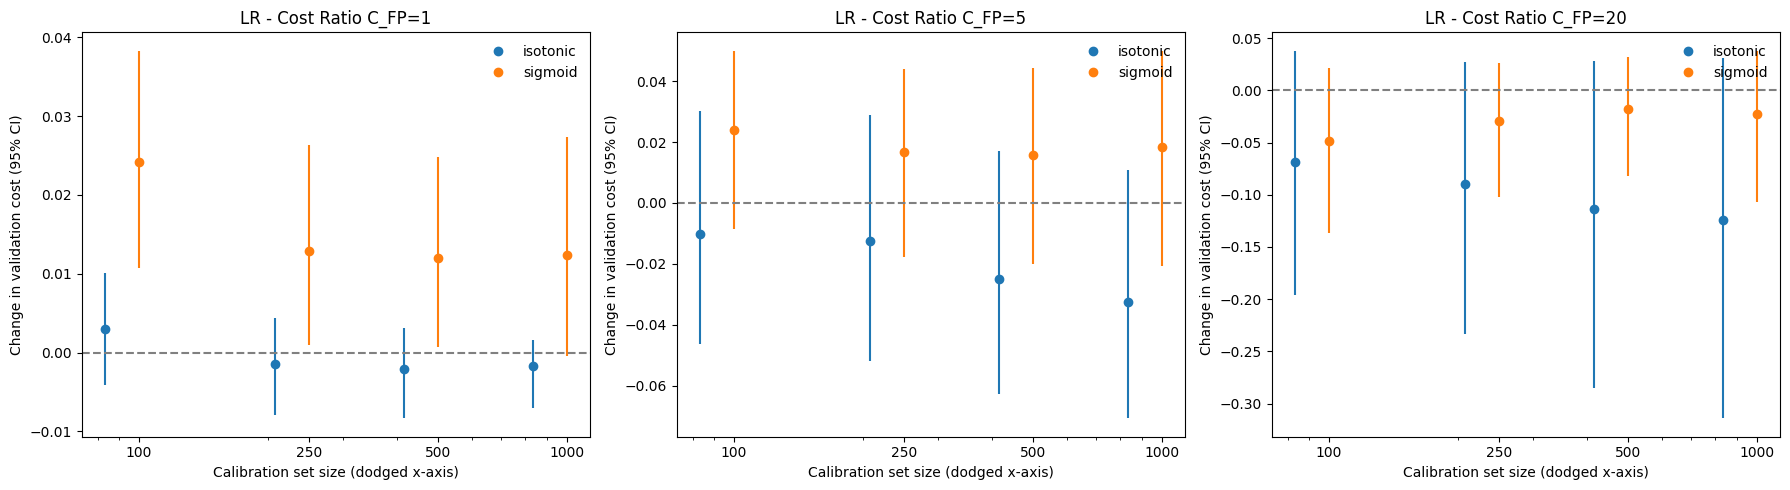

In [ ]:
plot_calibration_costs(lr_bootstrap_df, 'LR')

Analyzing the changes in validation expected cost and their corresponding 95% paired bootstrap confidence intervals for Logistic Regression reveals several patterns:

- **Sigmoid Calibration (Platt Scaling):**
  - Under symmetric misclassification costs ($C_{FP}=1$), sigmoid calibration produces statistically supported **increases** in expected cost at $n=100,250,500$ using the unadjusted intervals.
  - At $C_{FP}=5$, the estimated cost increases remain relatively stable as the calibration sample size increases, although all confidence intervals contain zero (indicating **inconclusive** change in expected costs).
  - At $C_{FP}=20$, sigmoid calibration produces estimated **reductions** in expected cost across all tested calibration sample sizes, but the results remain inconclusive.

- **Isotonic Calibration:**
  - Under symmetric misclassification costs ($C_{FP}=1$), the change in expected costs is **inconclusive**.
  - Under asymmetric misclassification costs ($C_{FP}=5$ and $C_{FP}=20$), isotonic calibration consistently produces estimated cost **reductions**, with larger reductions observed at larger calibration sample sizes.

Overall, neither calibration method demonstrates a statistically supported reduction in expected cost on the current validation partition. These findings remain exploratory.

## Probability Reliability Curve

In this section, we examine the probability reliability of the uncalibrated Logistic Regression model and its recalibrated variants on the validation set.

We use reliability diagrams to investigate how calibration sample size affects probability reliability and whether the observed calibration patterns help explain the changes in cost-sensitive decision performance.

### Uncalibrated vs. Calibrated Models

We will visualize how different calibration sample sizes ($n$) alter the probability reliability curves (reliability diagrams) of Logistic Regression on the validation set.

In [ ]:
def plot_reliability_diagrams(base_model, X_cal, y_cal, X_eval, y_eval, model_name):
    """
    Plots side-by-side reliability diagrams (calibration curves) on the test set comparing
    the uncalibrated baseline model against its Sigmoid (Platt) and Isotonic calibrated variants.

    Evaluates calibration behavior across representative small (n=100) and large (n=1000)
    calibration subsets sampled randomly from the provided calibration pool.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    rng = np.random.default_rng(SEED)

    for i, n in enumerate([100, 1000]):
        ax = axes[i]
        # Draw the calibration subset
        idx = rng.choice(len(y_cal), n, replace=False)
        X_cal_sub, y_cal_sub = X_cal.iloc[idx], y_cal.iloc[idx]

        # Plot baseline (uncalibrated)
        CalibrationDisplay.from_estimator(base_model, X_eval, y_eval, n_bins=10, name="Baseline (Uncal)", ax=ax, color='black', linestyle='--')

        # Fit and plot Sigmoid
        cal_sig = CalibratedClassifierCV(FrozenEstimator(base_model), method='sigmoid')
        cal_sig.fit(X_cal_sub, y_cal_sub)
        CalibrationDisplay.from_estimator(cal_sig, X_eval, y_eval, n_bins=10, name="Sigmoid (Platt)", ax=ax, color='blue')

        # Fit and plot Isotonic
        cal_iso = CalibratedClassifierCV(FrozenEstimator(base_model), method='isotonic')
        cal_iso.fit(X_cal_sub, y_cal_sub)
        CalibrationDisplay.from_estimator(cal_iso, X_eval, y_eval, n_bins=10, name="Isotonic", ax=ax, color='red')

        ax.set_title(f"{model_name} Calibration Reliability (n={n})")
        ax.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

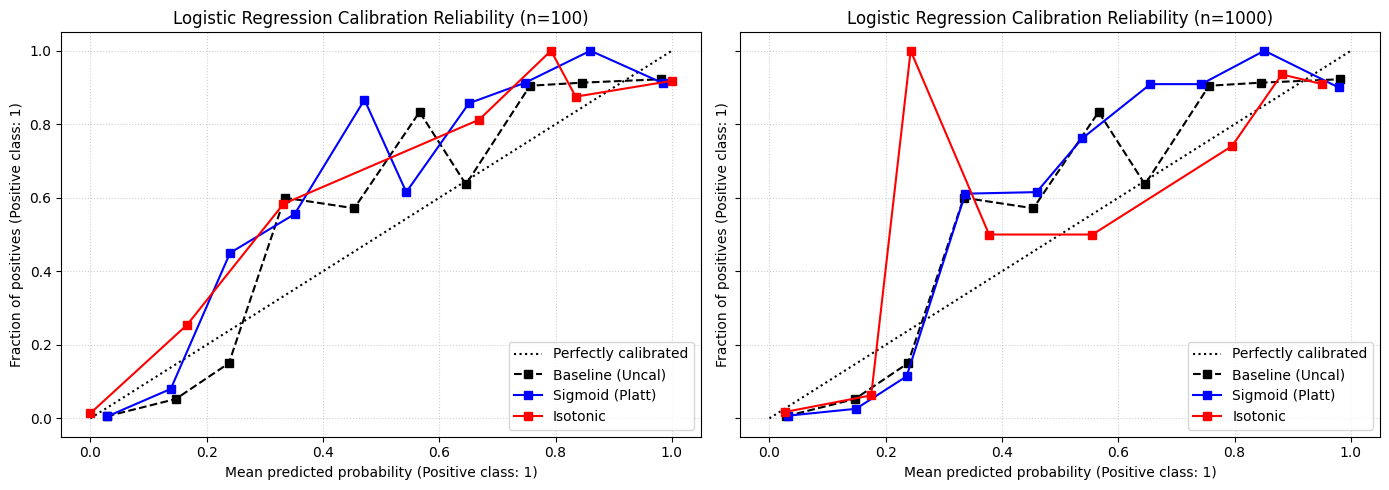

In [ ]:
# Plot for Logistic Regression
plot_reliability_diagrams(spam_lr, X_spam_cal, y_spam_cal, X_spam_val, y_spam_val, "Logistic Regression")

The reliability diagrams reveal that the uncalibrated Logistic Regression model exhibits reasonably good but imperfect probability calibration, particularly **underestimating** the observed positive-class frequency across intermediate probability ranges.

- **Sigmoid Calibration (Platt Scaling):**
  - Sigmoid recalibration does not consistently improve probability reliability. Similar deviations from the ideal calibration line remain at both calibration sample sizes ($n=100$ and $n=1000$).
- **Isotonic Calibration:**
  - Isotonic recalibration exhibits substantial fluctuations at the largest calibration size ($n=1000$).
  
Increasing the calibration size does not consistently improve the reliability curve in these illustrative draws. These observations should therefore be considered alongside the Brier scores, log-loss values, and paired confidence intervals for changes in expected cost.

### Platt (Sigmoid) Calibration

At the moderately asymmetric cost ratio ($C_{FP}=5$, $C_{FN}=1$), Platt recalibration produces a persistent increase in validation expected cost across all tested calibration sample sizes.

To investigate this behavior, we verify the input representation used by the sigmoid calibrator and examine changes in Brier score, log loss, and expected cost relative to the uncalibrated baseline.

In [ ]:
p = spam_lr.predict_proba(X_spam_val)[:, 1]
z = spam_lr.decision_function(X_spam_val)

print("Decision function available:", hasattr(FrozenEstimator(spam_lr), 'decision_function'))

print("Decision function represents log-odds:", np.allclose(expit(z), p))

Decision function available: True
Decision function represents log-odds: True


The implementation verification confirms that the Logistic Regression model's decision function represents log-odds and is available to the sigmoid calibrator. Therefore, the observed deterioration is **unlikely** to be caused by fitting the sigmoid directly on predicted probabilities.

In [ ]:
baseline = lr_calibration_results.query("method == 'none' & c_fp == 5").iloc[0]

metrics = ['brier', 'logloss', 'cost']

# Compute the difference in performance metrics with the uncalibrated model
platt_diagnosis = (
    lr_calibration_results.query("method == 'sigmoid' & c_fp == 5")
    .groupby('n')[metrics].mean() - baseline[metrics].astype(float)
    )

display(platt_diagnosis.round(4))

,brier,logloss,cost
n,,,
100,0.0147,0.0179,0.0239
250,0.0085,0.0042,0.0169
500,0.0073,-0.0002,0.0159
1000,0.0074,-0.0025,0.0185


At the moderately asymmetric cost ratio ($C_{FP}=5$, $C_{FN}=1$), **Platt** recalibration increases the Brier score and expected cost relative to the uncalibrated baseline across all tested calibration sample sizes. However, slight improvements in log loss are observed at $n=500$ and $n=1000$.

Although the deterioration in Brier score generally decreases as the calibration sample size increases, the increase in expected cost persists, ranging from 0.0159 to 0.0239.

These findings suggest that limited calibration data alone may not explain the deterioration in cost-sensitive performance. Furthermore, improvements in overall probability quality do not necessarily translate into reductions in expected cost at a particular decision threshold.

# 1.2. Random Forest

## Model Training

As a comparison, we will train a Random Forest on the **training set** (`X_spam_train`, `y_spam_train`). We did not tune the model's hyperparameter because the **objective** of this study is not to optimize classifier performance, but to investigate how recalibration and calibration sample size affect probability reliability and cost-sensitive decision-making under fixed base-model configurations.

In [ ]:
# Train the Random Forest model on training data
spam_rf = create_pipeline(RandomForestClassifier(random_state=SEED), [], spam_feature_cols)
spam_rf.fit(X_spam_train, y_spam_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(force_int_remainder_cols=False,
                                   remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  []),
                                                 ('num', StandardScaler(),
                                                  ['word_freq_make',
                                                   'word_freq_address',
                                                   'word_freq_all',
                                                   'word_freq_3d',
                                                   'word_freq_our',
                                                   'word_freq_over',
                                                   'word_freq_remove',
                                                   'word_freq_internet',
                                                   'word_freq_orde...
                                                   'word_freq_report',
                                                   'word_freq_addresses',
                                                   'word_freq_free',
                                                   'word_freq_business',
                                                   'word_freq_email',
                                                   'word_freq_you',
                                                   'word_freq_credit',
                                                   'word_freq_your',
                                                   'word_freq_font',
                                                   'word_freq_000',
                                                   'word_freq_money',
                                                   'word_freq_hp',
                                                   'word_freq_hpl',
                                                   'word_freq_george',
                                                   'word_freq_650',
                                                   'word_freq_lab',
                                                   'word_freq_labs', ...])])),
                ('classifier', RandomForestClassifier(random_state=42))])

## Model Calibration

Random Forest estimates class probabilities by averaging the probability predictions of its individual decision trees. This averaging can produce systematic miscalibration, although the degree and direction of miscalibration depend on the dataset and model configuration.

We investigate whether Platt scaling (`sigmoid`) and isotonic regression can improve probability reliability and reduce expected costs relative to the uncalibrated Random Forest baseline.

We use the same experimental methodology as Logistic Regression, drawing calibration subsets of sizes $n \in \{100,250,500,1000\}$ over 50 random calibration draws and evaluating performance on the validation set.

In [ ]:
# Run the calibration experiment for Random Forest using our custom function
rf_calibration_results, rf_differences = run_calibration_experiment(
    model=spam_rf,
    X_train=X_spam_train,
    y_train=y_spam_train,
    X_cal=X_spam_cal,
    y_cal=y_spam_cal,
    X_eval=X_spam_val,
    y_eval=y_spam_val,
    seed=SEED
)

print(rf_calibration_results.groupby(['c_fp', 'method', 'n']).agg(['mean', 'std']).round(4))

                     brier         logloss            cost        
                      mean     std    mean     std    mean     std
c_fp method   n                                                   
1    isotonic 100   0.0547  0.0065  0.8196  0.5136  0.0672  0.0135
              250   0.0520  0.0025  0.3860  0.2872  0.0661  0.0074
              500   0.0503  0.0017  0.2440  0.1002  0.0653  0.0050
              1000  0.0498  0.0011  0.1820  0.0168  0.0670  0.0027
     none     0     0.0509     NaN  0.1857     NaN  0.0576     NaN
     sigmoid  100   0.0507  0.0046  0.1860  0.0164  0.0618  0.0078
              250   0.0496  0.0016  0.1808  0.0059  0.0599  0.0046
              500   0.0489  0.0009  0.1776  0.0033  0.0585  0.0034
              1000  0.0490  0.0006  0.1776  0.0022  0.0579  0.0023
5    isotonic 100   0.0547  0.0065  0.8196  0.5136  0.1260  0.0288
              250   0.0520  0.0025  0.3860  0.2872  0.1243  0.0130
              500   0.0503  0.0017  0.2440  0.1002  0.1239  0.

Across all tested cost ratios and calibration sample sizes, both the uncalibrated and recalibrated Random Forest models achieve lower mean expected costs than the constant-decision baselines.

Unlike Logistic Regression, Random Forest maintains a lower observed mean expected cost than the always-negative strategy even under highly asymmetric misclassification costs ($C_{FP}=20$).

These comparisons provide a practical reference for the classifier's decision-making performance but do not establish statistical superiority over the constant-decision strategies.

## Confidence Interval

We will apply the same group-aware paired bootstrap procedure to Random Forest to estimate changes in the validation expected cost.

In [ ]:
# Calculate 95% Bootstrap Confidence Intervals for Random Forest
rf_bootstrap_df = bootstrap_ci(rf_differences, spam_groups, spam_parts)

## Plotting Cost Differences

We will visualize changes in Random Forest validation expected cost with the **unadjusted** 95% paired bootstrap confidence intervals.

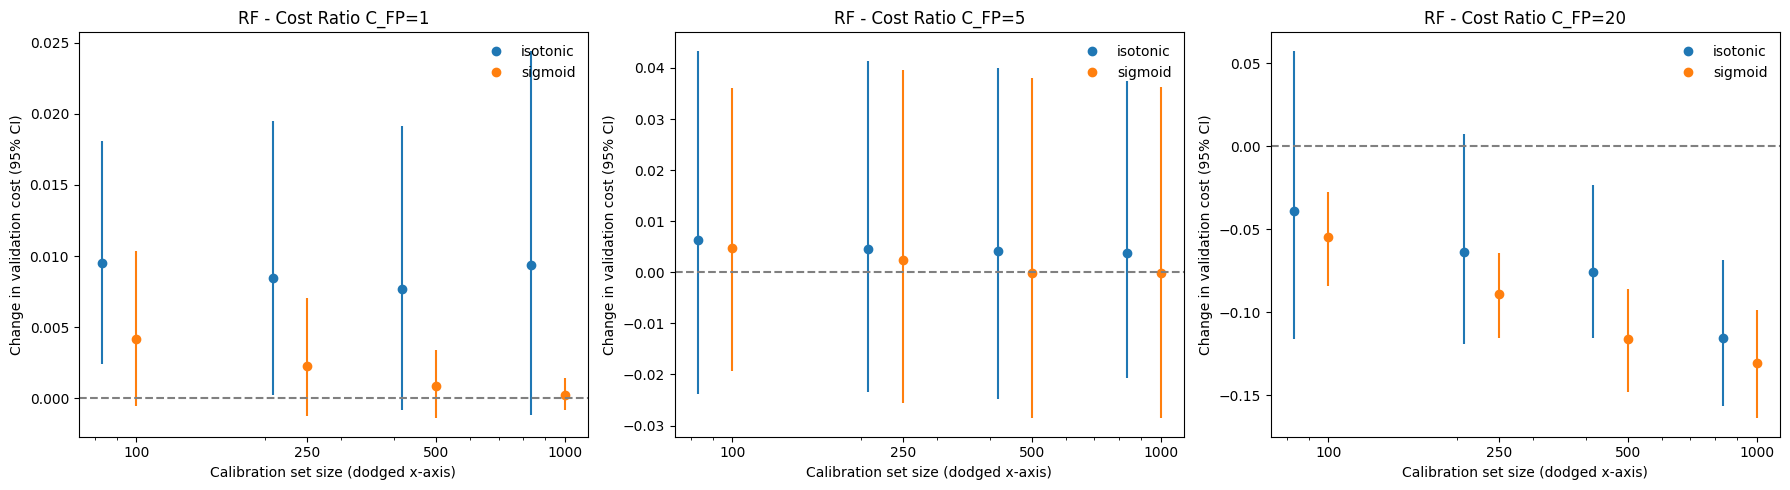

In [ ]:
plot_calibration_costs(rf_bootstrap_df, 'RF')

Analyzing the changes in validation expected cost and their corresponding 95% paired bootstrap confidence intervals for Random Forest reveals several patterns:

- **Sigmoid Calibration (Platt Scaling):**
  - At $C_{FP}=1$ and $C_{FP}=5$, the estimated changes in expected cost remain relatively close to zero, with all confidence intervals containing zero (change in expected costs is **inconclusive**).
  - At $C_{FP}=20$, sigmoid calibration produces **cost reductions** across all tested calibration sample sizes, with the **unadjusted** confidence intervals lying strictly below zero.

- **Isotonic Calibration:**
  - At $C_{FP}=1$, isotonic calibration produces estimated increases in expected cost.
  - At $C_{FP}=5$, the change in cost is **inconclusive**.
  - At $C_{FP}=20$, isotonic calibration produces increasingly substantial **cost reductions**, with the **unadjusted** confidence intervals lying strictly below zero at $n=500$ and $n=1000$.

These findings suggest that recalibration may benefit Random Forest under highly asymmetric misclassification costs. However, the results remain **exploratory** because the confidence intervals are **unadjusted** for multiple comparisons.

## Probability Reliability Curves

Similarly, we plot the reliability diagrams for the Random Forest classifier on the validation set to evaluate how calibration sizes impact probability reliability.

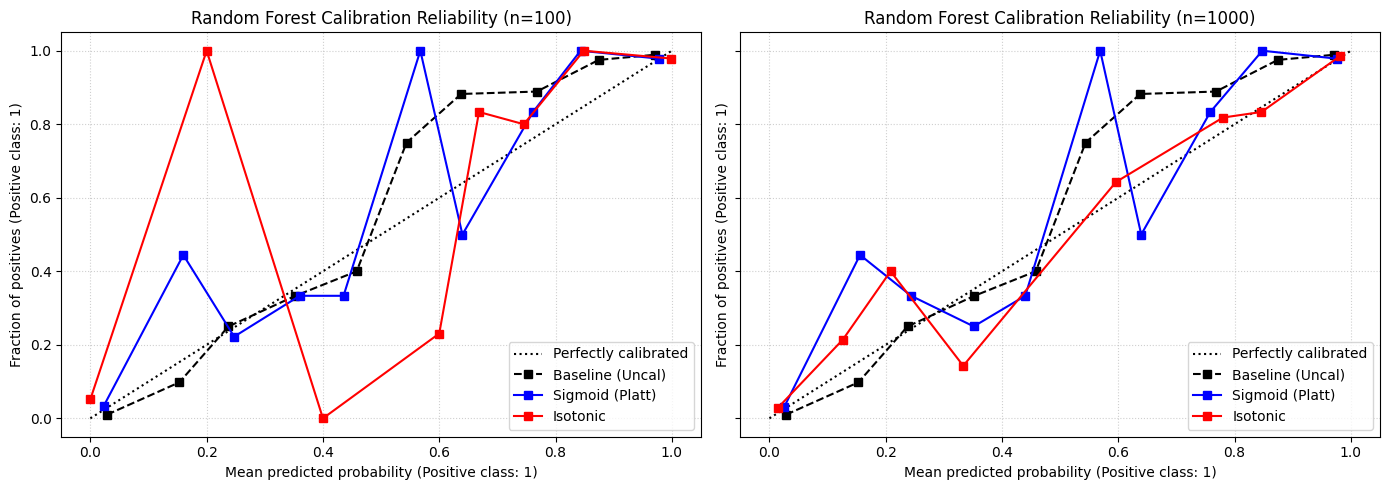

In [ ]:
# Plot for Random Forest
plot_reliability_diagrams(spam_rf, X_spam_cal, y_spam_cal, X_spam_val, y_spam_val, "Random Forest")

The reliability diagrams reveal that the uncalibrated Random Forest model exhibits systematic miscalibration, particularly **underestimating** the observed positive-class frequency at higher predicted probabilities.

- **Sigmoid Calibration (Platt Scaling):**
  - Sigmoid recalibration partially corrects the miscalibration of the uncalibrated baseline, although substantial fluctuations remain at intermediate probabilities.
- **Isotonic Calibration:**
  - At $n=100$, isotonic recalibration exhibits substantial fluctuations across the probability range.
  - At $n=1000$, the reliability curve becomes smoother and aligns more closely with the ideal calibration line across several probability regions, suggesting that larger calibration samples may benefit this nonparametric approach.

Nevertheless, these illustrative improvements in probability reliability do not necessarily translate into reductions in expected cost.

# 1.3. Outer-Split Evaluation

To assess the robustness of the preliminary findings, we repeat the experimental pipeline over 20 prespecified **outer split** seeds.

For each outer split, the dataset is partitioned into stratified, duplicate-group-disjoint training, calibration, validation, and test sets. The base classifiers are independently retrained using fixed hyperparameter configurations, followed by repeated calibration experiments.

The model hyperparameters, calibration sample sizes, misclassification cost ratios, and primary comparisons are fixed before examining the final test results.

Previously examined results (Parts `1.1.` and `1.2.`) are treated as **exploratory**. The repeated outer-split evaluation assesses the robustness of the observed recalibration effects across different data partitions, fitted models, and calibration samples.

## Model Pipeline Configurations

The exploratory cross-validation for Logistic Regression selects $C=0.1$. However, we will **fix** the default $C=1$ for the repeated outer-split experiments to maintain the established model configuration.

In [ ]:
LR_PARAMS = {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 2000}

We will explicitly list out Random Forest's default hyperparameters for clarity. These hyperparameters will remained **fixed** during repeated outer-split evaluations.

In [ ]:
RF_PARAMS = {
    'n_estimators': 100,
    'criterion': 'gini',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'max_features': 'sqrt',
    'bootstrap': True
}

To maintain a consistent experimental methodology across both datasets, we will define dataset-specific model pipelines separately from the outer-split evaluation function.

Each pipeline specifies the corresponding preprocessing procedures, feature selection, and fixed model hyperparameters. During each outer split, the pipelines are **cloned** to ensure that model parameters and preprocessing transformations are fitted independently using the corresponding training partition.

In [ ]:
spam_models = {
    'LR': create_pipeline(LogisticRegression(**LR_PARAMS), [], spam_feature_cols, drop='first'),
    'RF': create_pipeline(RandomForestClassifier(**RF_PARAMS), [], spam_feature_cols)
}

## Single Outer-Split Evaluation

For each outer split, we will perform the following procedures:

1. Construct stratified, duplicate-group-disjoint data partitions using a specified random seed.
2. Initialize and train Logistic Regression and Random Forest using their fixed configurations.
3. Perform repeated Platt and isotonic calibration experiments for each calibration sample size.
4. Evaluate probability quality and cost-sensitive decision performance on the designated evaluation partition.
5. Record observation-level paired cost differences and constant-decision reference costs.

The evaluation observation indices and duplicate-group identifiers are retained to support subsequent uncertainty estimation and account for overlapping evaluation groups across outer splits.

In [ ]:
def run_outer_split(X, y, groups, models, seed, eval_part):

    # Generate new split
    parts = create_partitions(X, y, groups, seed)

    X_train = X[parts == 'train']
    y_train = y[parts == 'train']

    X_cal = X[parts == 'cal']
    y_cal = y[parts == 'cal']

    X_eval = X[parts == eval_part]
    y_eval = y[parts == eval_part]

    results = []
    all_differences = {}
    for model_name, model_template in models.items():
        # Create an independent, unfitted pipeline
        model = clone(model_template)

        # Set model random seed, if supported
        if 'classifier__random_state' in model.get_params():
            model.set_params(classifier__random_state=seed)

        model.fit(X_train, y_train)

        metrics, differences = run_calibration_experiment(
            model=model,
            X_train=X_train,
            y_train=y_train,
            X_cal=X_cal,
            y_cal=y_cal,
            X_eval=X_eval,
            y_eval=y_eval,
            seed=seed
        )

        metrics['model'] = model_name
        metrics['seed'] = seed

        results.append(metrics)
        all_differences[model_name] = differences

    constants = constant_decision_baselines(y_eval)
    constants['seed'] = seed

    return {
        'metrics': pd.concat(results, ignore_index=True),
        'differences': all_differences,
        'constants': constants,
        'eval_groups': np.asarray(groups)[parts == eval_part],
        'eval_indices': X_eval.index.to_numpy()
    }

## Final Evaluation Across Outer Splits

We will evaluate the classifiers across 20 prespecified outer split seeds.

Within each split, the **test** partition is reserved exclusively for evaluating the fixed experimental configurations. No further hyperparameter selection or methodological adjustments are performed based on the test results.

The resulting performance metrics, paired cost differences, constant-decision reference costs, and evaluation group identifiers are retained for subsequent statistical analysis.

Because repeated outer splits are constructed from the same underlying dataset, their evaluation observations may overlap. Consequently, the outer-split results are not treated as independent datasets.

In [ ]:
outer_results = {}
for seed in OUTER_SEEDS:
    print(f"Running outer split: {seed}")
    outer_results[seed] = run_outer_split(X_spam, y_spam, seed=seed, models=spam_models,
                                          groups=spam_groups, eval_part='test')

Running outer split: 2007
Running outer split: 2008
Running outer split: 2009
Running outer split: 2010
Running outer split: 2011
Running outer split: 2012
Running outer split: 2013
Running outer split: 2014
Running outer split: 2015
Running outer split: 2016
Running outer split: 2017
Running outer split: 2018
Running outer split: 2019
Running outer split: 2020
Running outer split: 2021
Running outer split: 2022
Running outer split: 2023
Running outer split: 2024
Running outer split: 2025
Running outer split: 2026


## Group-Aware Paired Bootstrap and Multiple-Comparison Adjustment

We will average paired cost differences across calibration draws and jointly resample duplicate groups across outer splits to account for overlapping test observations.

Note that conducting multiple comparisons increases the risk of obtaining a statistically significant result by chance. The **Bonferroni correction** addresses this by requiring stronger evidence for each individual comparison. Additionally, **group-aware paired bootstrap intervals** help measure uncertainty without falsely assuming the repeated splits are independent.

Using 10,000 bootstrap iterations, we will construct three confidence intervals with Bonferroni adjustments:

- **95% CI:** Individual cost comparisons (unadjusted).
- **98.75% CI:** Adjustment across the four primary comparisons.
- **99.375% CI:** Adjustment within each family of eight comparisons (two calibration methods × four sample sizes) for a fixed dataset, classifier, and cost ratio.

The **family**-adjusted intervals support the identification of the minimum effective calibration sample size. All intervals are conditional on the fitted models, outer partitions, and calibration draws.

In [ ]:
def bootstrap_outer_ci(outer_results, model_name, seed=SEED):
    rng = np.random.default_rng(seed)
    results = list(outer_results.values())

    # Preserve group identities across outer splits
    all_groups = np.concatenate([r['eval_groups'] for r in results])

    group_codes, unique_groups = pd.factorize(all_groups)
    n_groups = len(unique_groups)

    # Number of evaluation appearances per group
    group_counts = np.bincount(group_codes, minlength=n_groups)

    bootstrap_results = []
    n_bootstrap = 10_000

    keys = results[0]['differences'][model_name].keys()
    for c_fp, method, n in keys:
        key = (c_fp, method, n)

        # Average across calibration draws within each split
        avg_res = [np.asarray(r['differences'][model_name][key]).mean(axis=0) for r in results]
        differences = np.concatenate(avg_res)

        # Sum paired differences within each original group
        group_sums = np.bincount(group_codes, weights=differences, minlength=n_groups)

        boot_means = np.empty(n_bootstrap)

        for b in range(n_bootstrap):
            # Resample original duplicate groups
            sampled = rng.choice(n_groups, size=n_groups, replace=True)

            boot_means[b] = group_sums[sampled].sum() / group_counts[sampled].sum()

        ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])

        # Adjustment for primary comparisons
        primary_lower, primary_upper = np.quantile(boot_means, [ALPHA_PRIMARY / 2, 1 - ALPHA_PRIMARY / 2])

        # Adjustment for comparisons within each family
        family_lower, family_upper = np.quantile(boot_means, [ALPHA_FAMILY / 2, 1 - ALPHA_FAMILY / 2])

        if ci_lower > 0:
            outcome = 'Increase'
        elif ci_upper < 0:
            outcome = 'Decrease'
        else:
            outcome = 'Inconclusive'

        bootstrap_results.append({
            'c_fp': c_fp,
            'method': method,
            'n': n,
            'mean_difference': differences.mean(),
            '95% CI Lower': ci_lower,
            '95% CI Upper': ci_upper,
            'Unadjusted outcome': outcome,
            'Primary CI Lower': primary_lower,
            'Primary CI Upper': primary_upper,
            'Family CI Lower': family_lower,
            'Family CI Upper': family_upper
        })

    return pd.DataFrame(bootstrap_results)

In [ ]:
lr_outer_ci = bootstrap_outer_ci(outer_results, 'LR')
rf_outer_ci = bootstrap_outer_ci(outer_results, 'RF')

**Note**: Confidence intervals will be presented in section `Primary and Secondary Comparison Results`.

# 1.4. Results and Visualization

## Aggregated Performance Metrics

To summarize probability reliability and cost-sensitive decision performance across the repeated outer splits, we will aggregate the Brier scores, log-loss values, and expected expected costs for each experimental configuration.

Performance metrics are first averaged across calibration draws within each outer split and subsequently aggregated across the 20 **test** partitions, weighted by their respective sample sizes.

This weighting is consistent with the aggregation procedure used to construct the group-aware paired bootstrap confidence intervals.

In [ ]:
def aggregate_outer_metrics(outer_results):
    frames = []

    for seed, result in outer_results.items():
        df = result['metrics'].copy()
        df['n_eval'] = len(result['eval_groups'])
        frames.append(df)

    all_metrics = pd.concat(frames, ignore_index=True)

    config = ['model', 'c_fp', 'method', 'n']
    metrics = ['brier', 'logloss', 'cost']

    # Average across calibration draws within each split
    split_metrics = (all_metrics.groupby(['seed', 'n_eval'] + config)[metrics]
                     .mean().reset_index())

    # Weight by test partition size
    weighted = split_metrics.copy()

    for metric in metrics:
        weighted[metric] *= weighted['n_eval']

    summary = (weighted.groupby(config)[metrics + ['n_eval']].sum())

    # Calculate weighted mean performance
    for metric in metrics:
        summary[metric] /= summary['n_eval']

    return summary.drop(columns='n_eval').reset_index()

In [ ]:
outer_metrics = aggregate_outer_metrics(outer_results)

## Aggregated Probability Metrics

We report equally weighted means and standard deviations of Brier scores and log loss across the 20 outer splits, after averaging over calibration draws within each split.

Paired differences from the uncalibrated baseline assess the consistency of probability-quality improvements. Standard deviations describe variability across partitions rather than confidence intervals, as the outer splits are **not independent** (drawn from the same dataset).

In [ ]:
def summarize_probability_metrics(outer_results):
    metrics = ['brier', 'logloss']
    keys = ['model', 'method', 'n']

    df = pd.concat([r['metrics'] for r in outer_results.values()], ignore_index=True)

    # Probability metrics are independent of the cost ratio
    df = df[df['c_fp'] == C_FPS[0]]

    # Average across calibration draws within each split
    split_metrics = (df.groupby(['seed'] + keys)[metrics].mean().reset_index())

    # Convert to long format
    split_metrics = split_metrics.melt(
        id_vars=['seed'] + keys,
        value_vars=metrics,
        var_name='metric',
        value_name='value'
    )

    # Uncalibrated baseline within each split
    baseline = (split_metrics.query("method == 'none'")[['seed', 'model', 'metric', 'value']]
                .rename(columns={'value': 'baseline'}))

    # Paired differences
    paired = split_metrics.merge(baseline, on=['seed', 'model', 'metric'], validate='many_to_one')

    paired['difference'] = paired['value'] - paired['baseline']

    return (
        paired.groupby(keys + ['metric']).agg(
            mean=('value', 'mean'),
            std=('value', 'std'),
            mean_difference=('difference', 'mean'),
            difference_std=('difference', 'std')
        ).reset_index()
    )

In [ ]:
spam_probability_metrics = summarize_probability_metrics(outer_results)
lr_prob_metrics = spam_probability_metrics.query("model == 'LR'")
for metric in ['brier', 'logloss']:
    display(lr_prob_metrics.query("metric == @metric").round(4))

,model,method,n,metric,mean,std,mean_difference,difference_std
0,LR,isotonic,100,brier,0.0761,0.0088,0.0058,0.0021
2,LR,isotonic,250,brier,0.0728,0.0081,0.0025,0.0024
4,LR,isotonic,500,brier,0.0713,0.0083,0.0011,0.0026
6,LR,isotonic,1000,brier,0.0705,0.0083,0.0002,0.0028
8,LR,none,0,brier,0.0703,0.0086,0.0000,0.0000
10,LR,sigmoid,100,brier,0.0811,0.0078,0.0109,0.0039
12,LR,sigmoid,250,brier,0.0768,0.0082,0.0065,0.0039
14,LR,sigmoid,500,brier,0.0753,0.0083,0.0050,0.0036
16,LR,sigmoid,1000,brier,0.0745,0.0082,0.0042,0.0035


,model,method,n,metric,mean,std,mean_difference,difference_std
1,LR,isotonic,100,logloss,0.9487,0.2858,0.6573,0.2300
3,LR,isotonic,250,logloss,0.5647,0.1337,0.2733,0.0882
5,LR,isotonic,500,logloss,0.4023,0.0857,0.1109,0.0486
7,LR,isotonic,1000,logloss,0.3158,0.0621,0.0244,0.0509
9,LR,none,0,logloss,0.2914,0.0722,0.0000,0.0000
11,LR,sigmoid,100,logloss,0.2906,0.0418,-0.0008,0.0326
13,LR,sigmoid,250,logloss,0.2818,0.0455,-0.0096,0.0284
15,LR,sigmoid,500,logloss,0.2794,0.0486,-0.0120,0.0254
17,LR,sigmoid,1000,logloss,0.2779,0.0497,-0.0135,0.0246


- **Logistic Regression:**
  - Sigmoid calibration reduces mean **log loss** but increases the mean **Brier** score across all tested calibration sample sizes. The reductions in log loss remain smaller than their paired standard deviations.
  - Isotonic calibration performs worse than the uncalibrated baseline but approaches baseline performance as the calibration sample size increases.

In [ ]:
rf_prob_metrics = spam_probability_metrics.query("model == 'RF'")
for metric in ['brier', 'logloss']:
    display(rf_prob_metrics.query("metric == @metric").round(4))

,model,method,n,metric,mean,std,mean_difference,difference_std
18,RF,isotonic,100,brier,0.0531,0.0053,0.0019,0.0028
20,RF,isotonic,250,brier,0.0502,0.0052,-0.0010,0.0028
22,RF,isotonic,500,brier,0.0490,0.0052,-0.0022,0.0028
24,RF,isotonic,1000,brier,0.0482,0.0052,-0.0029,0.0029
26,RF,none,0,brier,0.0512,0.0038,0.0000,0.0000
28,RF,sigmoid,100,brier,0.0481,0.0046,-0.0031,0.0018
30,RF,sigmoid,250,brier,0.0474,0.0048,-0.0038,0.0021
32,RF,sigmoid,500,brier,0.0471,0.0049,-0.0040,0.0022
34,RF,sigmoid,1000,brier,0.0470,0.0049,-0.0042,0.0023


,model,method,n,metric,mean,std,mean_difference,difference_std
19,RF,isotonic,100,logloss,0.7386,0.1608,0.4887,0.1353
21,RF,isotonic,250,logloss,0.4404,0.1079,0.1904,0.0799
23,RF,isotonic,500,logloss,0.3077,0.0736,0.0577,0.0611
25,RF,isotonic,1000,logloss,0.2290,0.0478,-0.0210,0.0516
27,RF,none,0,logloss,0.2500,0.0596,0.0000,0.0000
29,RF,sigmoid,100,logloss,0.1790,0.0141,-0.0710,0.0565
31,RF,sigmoid,250,logloss,0.1744,0.0154,-0.0756,0.0556
33,RF,sigmoid,500,logloss,0.1727,0.0159,-0.0773,0.0552
35,RF,sigmoid,1000,logloss,0.1717,0.0161,-0.0783,0.0550


- **Random Forest:**
  - Sigmoid calibration improves both probability metrics across all tested calibration sample sizes, with the mean reductions exceeding their paired standard deviations.
  - Isotonic calibration also improves both metrics at $n=1000$, but these improvements are comparable to or smaller than their paired standard deviations. Substantial increases in log loss are observed at smaller calibration sample sizes.

These comparisons are descriptive rather than tests of statistical significance. Furthermore, improvements in probability quality do not necessarily translate into lower expected costs.

## Aggregated Constant-Decision Baselines

We will aggregate the costs of always predicting the positive or negative class across the 20 outer **test** partitions, weighted by their respective sample sizes. These costs serve as references for evaluating the practical performance of the uncalibrated and recalibrated classifiers.

In [ ]:
def aggregate_constant_baselines(outer_results):
    frames = []

    for result in outer_results.values():
        df = result['constants'].copy()
        df['n_eval'] = len(result['eval_groups'])
        frames.append(df)

    combined = pd.concat(frames, ignore_index=True)

    metrics = ['always_positive', 'always_negative']

    # Weight by test partition size
    for metric in metrics:
        combined[metric] *= combined['n_eval']

    summary = (combined.groupby(['c_fp', 'c_fn'])[metrics + ['n_eval']].sum())

    for metric in metrics:
        summary[metric] /= summary['n_eval']

    return summary.drop(columns='n_eval').reset_index()

In [ ]:
outer_constants = aggregate_constant_baselines(outer_results)

display(outer_constants.round(4))

,c_fp,c_fn,always_positive,always_negative
0,1,1,0.6082,0.3918
1,5,1,3.0412,0.3918
2,20,1,12.1647,0.3918


The always-negative strategy incurs a mean cost of 0.3918 across all three cost ratios, while the always-positive strategy incurs costs of 0.6082, 3.0412, and 12.1647, respectively. These values serve as practical reference costs for the classifiers.

## Primary and Secondary Comparison Results

We will combine the aggregated performance metrics with the paired bootstrap confidence intervals and constant-decision reference costs. Prespecified primary comparisons are distinguished from secondary comparisons, with Bonferroni-adjusted intervals used for statistical inference.

In [ ]:
def summarize_outer_results(outer_metrics, lr_outer_ci, rf_outer_ci, outer_constants, primary_comparisons):
    # Combine bootstrap results from both classifiers
    all_ci = pd.concat([lr_outer_ci.assign(model='LR'), rf_outer_ci.assign(model='RF')], ignore_index=True)

    keys = ['model', 'c_fp', 'method', 'n']

    # Combine absolute metrics with paired cost differences
    summary = all_ci.merge(outer_metrics, on=keys, validate='one_to_one')

    # Uncalibrated reference costs
    baseline = (outer_metrics.query("method == 'none'")[['model', 'c_fp', 'cost']]
                .rename(columns={'cost': 'baseline_cost'}))

    summary = summary.merge(baseline, on=['model', 'c_fp'], validate='many_to_one')

    # Constant-decision reference costs
    summary = summary.merge(outer_constants, on='c_fp', validate='many_to_one')

    # Identify primary comparisons
    summary['comparison_type'] = 'Secondary'

    for model, config in primary_comparisons.items():
        mask = (
            (summary['model'] == model)
            & (summary['method'] == config['method'])
            & (summary['n'] == config['n'])
            & (summary['c_fp'] == config['c_fp'])
            & (summary['c_fn'] == config['c_fn'])
        )
        summary.loc[mask, 'comparison_type'] = 'Primary'

    # Identify outcomes using family-adjusted intervals
    summary['family_outcome'] = np.select(
        [
            summary['Family CI Lower'] > 0,
            summary['Family CI Upper'] < 0
        ],
        ['Increase', 'Decrease'],
        default='Inconclusive'
    )

    # Primary-adjusted outcome (primary comparisons only)
    summary['primary_outcome'] = 'Not applicable'

    primary = summary['comparison_type'] == 'Primary'

    summary.loc[primary, 'primary_outcome'] = np.select(
        [
            summary.loc[primary, 'Primary CI Lower'] > 0,
            summary.loc[primary, 'Primary CI Upper'] < 0
        ],
        ['Increase', 'Decrease'],
        default='Inconclusive'
    )

    return summary

In [ ]:
spam_final_results = summarize_outer_results(
    outer_metrics,
    lr_outer_ci,
    rf_outer_ci,
    outer_constants,
    SPAM_PRIMARY_COMPARISONS
)

primary_cols = ['model', 'c_fp', 'method', 'n', 'baseline_cost', 'cost', 'mean_difference',
                'Primary CI Lower', 'Primary CI Upper', 'primary_outcome']

display(spam_final_results.query("comparison_type == 'Primary'")[primary_cols].round(4))

,model,c_fp,method,n,baseline_cost,cost,mean_difference,Primary CI Lower,Primary CI Upper,primary_outcome
19,LR,5,sigmoid,1000,0.2188,0.2348,0.0160,-0.0033,0.0293,Inconclusive
43,RF,5,sigmoid,1000,0.1432,0.1166,-0.0266,-0.0420,-0.0089,Decrease


For the prespecified **primary** comparisons (sigmoid calibration, $n=1000$, and $C_{FP}:C_{FN}=5:1$):

- **Logistic Regression:** Expected cost increases by 0.0160, but the 98.75% adjusted CI $[-0.0033,0.0293]$ indicates an **inconclusive** result.
- **Random Forest:** Expected cost decreases by 0.0266, with the adjusted CI $[-0.0420,-0.0089]$ supporting a **cost reduction**.

These results suggest that the effectiveness of recalibration depends on the base classifier.

The tables below present the full primary and secondary comparison results.

In [ ]:
result_cols = ['model', 'c_fp', 'method', 'n', 'baseline_cost', 'cost',
               'mean_difference', '95% CI Lower', '95% CI Upper',
               'Family CI Lower', 'Family CI Upper', 'family_outcome', 'comparison_type']

lr_final_results = spam_final_results.query("model == 'LR'")
display(lr_final_results[result_cols].sort_values(['model', 'c_fp', 'method', 'n']).round(4))

,model,c_fp,method,n,baseline_cost,cost,mean_difference,95% CI Lower,95% CI Upper,Family CI Lower,Family CI Upper,family_outcome,comparison_type
3,LR,1,isotonic,100,0.0864,0.0927,0.0063,0.0040,0.0087,0.0031,0.0100,Increase,Secondary
9,LR,1,isotonic,250,0.0864,0.0885,0.0020,-0.0000,0.0041,-0.0009,0.0049,Inconclusive,Secondary
15,LR,1,isotonic,500,0.0864,0.0865,0.0001,-0.0021,0.0022,-0.0030,0.0031,Inconclusive,Secondary
21,LR,1,isotonic,1000,0.0864,0.0844,-0.0020,-0.0042,0.0001,-0.0050,0.0009,Inconclusive,Secondary
0,LR,1,sigmoid,100,0.0864,0.0988,0.0123,0.0098,0.0149,0.0089,0.0160,Increase,Secondary
6,LR,1,sigmoid,250,0.0864,0.0951,0.0086,0.0064,0.0108,0.0055,0.0118,Increase,Secondary
12,LR,1,sigmoid,500,0.0864,0.0934,0.0070,0.0050,0.0090,0.0042,0.0099,Increase,Secondary
18,LR,1,sigmoid,1000,0.0864,0.0929,0.0065,0.0045,0.0085,0.0037,0.0093,Increase,Secondary
4,LR,5,isotonic,100,0.2188,0.2427,0.0239,0.0146,0.0322,0.0107,0.0350,Increase,Secondary
10,LR,5,isotonic,250,0.2188,0.2375,0.0187,0.0107,0.0261,0.0070,0.0287,Increase,Secondary


In [ ]:
rf_final_results = spam_final_results.query("model == 'RF'")
display(rf_final_results[result_cols].sort_values(['model', 'c_fp', 'method', 'n']).round(4))

,model,c_fp,method,n,baseline_cost,cost,mean_difference,95% CI Lower,95% CI Upper,Family CI Lower,Family CI Upper,family_outcome,comparison_type
27,RF,1,isotonic,100,0.0624,0.0663,0.0039,0.0020,0.0056,0.0012,0.0062,Increase,Secondary
33,RF,1,isotonic,250,0.0624,0.0640,0.0016,0.0001,0.0031,-0.0005,0.0036,Inconclusive,Secondary
39,RF,1,isotonic,500,0.0624,0.0634,0.0010,-0.0004,0.0024,-0.0010,0.0030,Inconclusive,Secondary
45,RF,1,isotonic,1000,0.0624,0.0632,0.0008,-0.0007,0.0024,-0.0013,0.0031,Inconclusive,Secondary
24,RF,1,sigmoid,100,0.0624,0.0621,-0.0003,-0.0011,0.0006,-0.0014,0.0009,Inconclusive,Secondary
30,RF,1,sigmoid,250,0.0624,0.0617,-0.0007,-0.0016,0.0002,-0.0019,0.0005,Inconclusive,Secondary
36,RF,1,sigmoid,500,0.0624,0.0617,-0.0007,-0.0016,0.0002,-0.0021,0.0006,Inconclusive,Secondary
42,RF,1,sigmoid,1000,0.0624,0.0619,-0.0005,-0.0015,0.0005,-0.0019,0.0009,Inconclusive,Secondary
28,RF,5,isotonic,100,0.1432,0.1371,-0.0062,-0.0224,0.0146,-0.0273,0.0241,Inconclusive,Secondary
34,RF,5,isotonic,250,0.1432,0.1296,-0.0137,-0.0288,0.0047,-0.0333,0.0131,Inconclusive,Secondary


## Cost-Sensitive Performance

We visualize the aggregated changes in test expected cost across calibration sample sizes and cost ratios, using group-aware paired 95% bootstrap confidence intervals. Negative cost differences indicate observed improvements relative to the uncalibrated baseline.

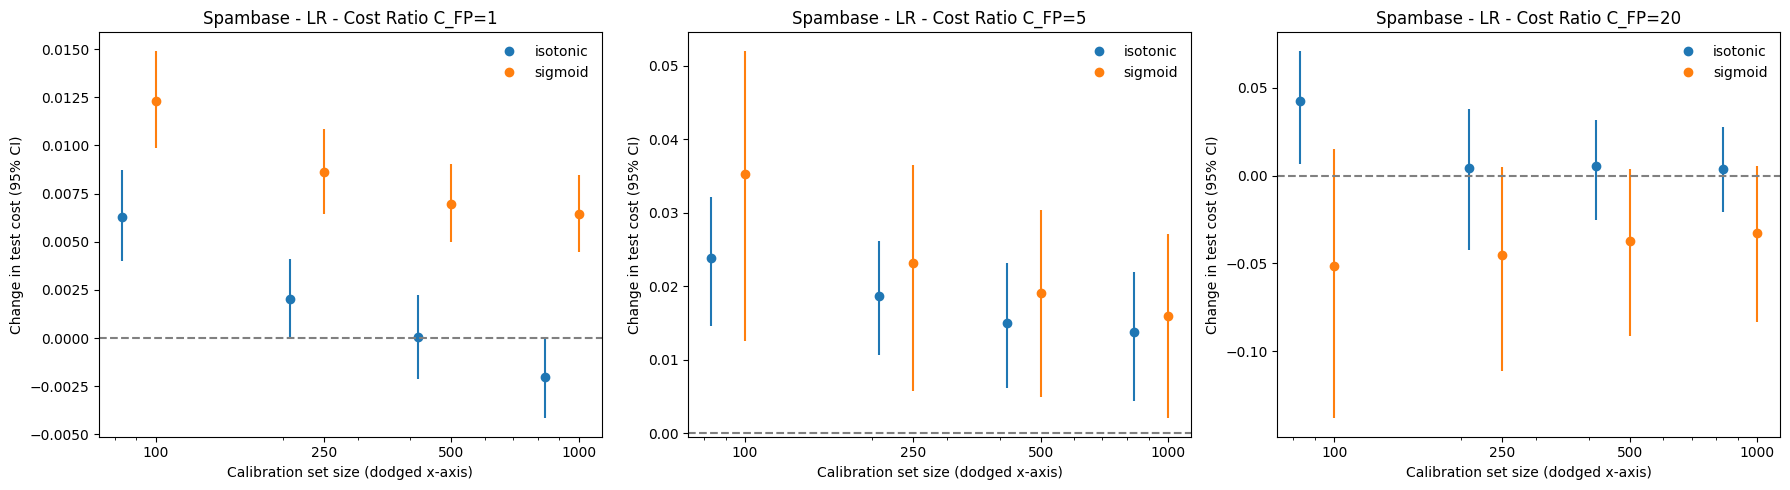

In [ ]:
plot_calibration_costs(lr_outer_ci, 'Spambase - LR', eval_name='test')

Based on the final cost differences and family-adjusted confidence intervals:

- **Logistic Regression:**
  - Under symmetric misclassification costs ($C_{FP}=1$), sigmoid calibration produces statistically supported **increases** in expected cost across all tested calibration sample sizes. Isotonic calibration produces an observed but **inconclusive** reduction at $n=1000$.
  - At $C_{FP}=5$, **both** calibration methods **increase** mean expected cost. **Isotonic** calibration produces statistically supported increases across all tested calibration sample sizes, whereas **sigmoid** calibration produces a supported (by **famiily-adjusted** intervals) increase only at $n=100$.
  - At $C_{FP}=20$, **sigmoid** calibration produces observed but statistically **inconclusive cost reductions**, while **isotonic** calibration produces **inconclusive** cost deterioration.

Overall, neither calibration method demonstrates a family-adjusted supported reduction in expected cost for Logistic Regression.

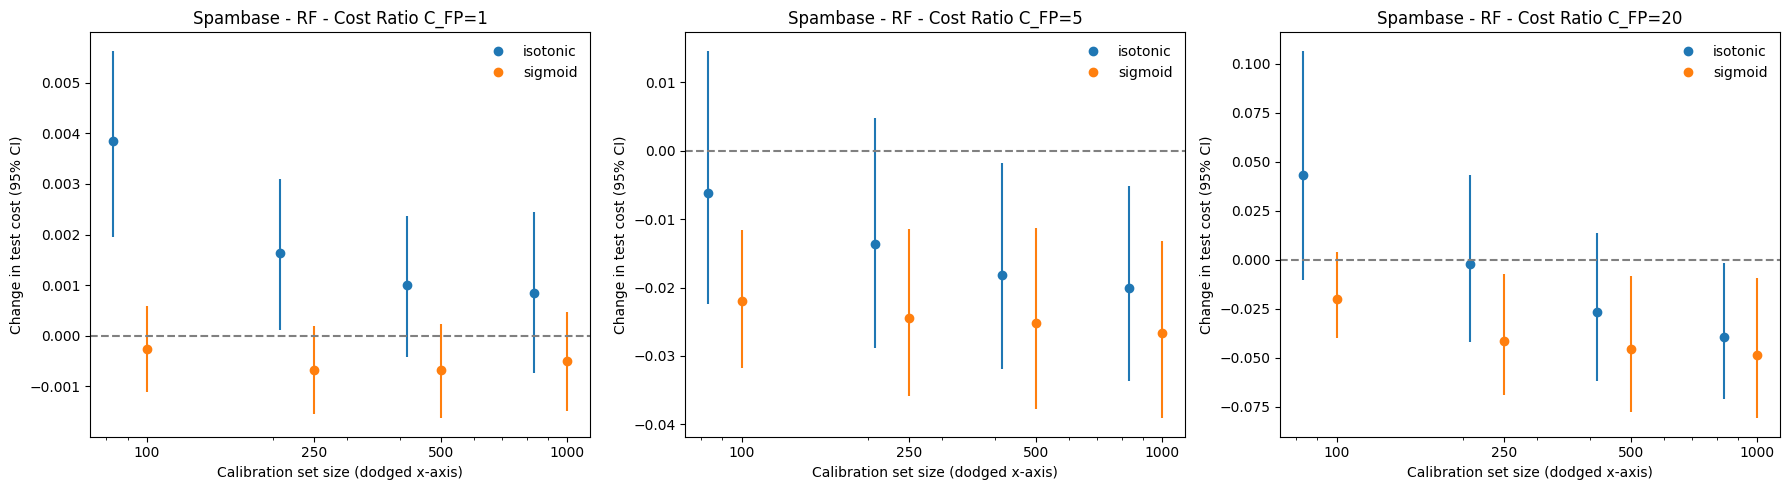

In [ ]:
plot_calibration_costs(rf_outer_ci, 'Spambase - RF', eval_name='test')

- **Random Forest:**
  - Under symmetric misclassification costs ($C_{FP}=1$), **isotonic** calibration **increases** observed expected cost, while **sigmoid** calibration produces small and **inconclusive cost reductions**.
  - At $C_{FP}=5$, **sigmoid** calibration produces statistically supported **cost reductions** across all tested calibration sample sizes. **Isotonic** calibration also **reduces** observed expected cost, but its family-adjusted confidence intervals contain zero.
  - At $C_{FP}=20$, sigmoid calibration and most isotonic calibration configurations reduce observed expected cost. However, all family-adjusted confidence intervals contain zero.

Overall, recalibration effectiveness depends on the classifier, calibration method, and misclassification cost ratio. The plotted 95% confidence intervals are **unadjusted**, while the statistical conclusions above use the family-adjusted intervals.

## Robustness Across Outer Splits

We will examine the variability of mean decision-cost changes across the 20 outer splits to assess the consistency of recalibration effects across different data partitions and fitted models.

**Note**: `improvement_fraction` represents the proportion of outer splits in which the mean expected cost of the recalibrated model is strictly lower than that of the uncalibrated baseline.

In [ ]:
def summarize_split_variability(outer_results):
    rows = []
    for seed, result in outer_results.items():
        for model, configs in result['differences'].items():
            for (c_fp, method, n), differences in configs.items():
                rows.append({
                    'seed': seed,
                    'model': model,
                    'c_fp': c_fp,
                    'method': method,
                    'n': n,
                    'delta_cost': np.asarray(differences).mean()
                })
    split_results = pd.DataFrame(rows)

    return (split_results.groupby(['model', 'c_fp', 'method', 'n'])['delta_cost']
            .agg(split_mean='mean', split_std='std', minimum='min', maximum='max',
                 improvement_fraction=lambda x: (x < 0).mean())
            .reset_index())

In [ ]:
spam_robustness = summarize_split_variability(outer_results)
lr_robustness = spam_robustness.query("model == 'LR'")
display(lr_robustness.round(4))

,model,c_fp,method,n,split_mean,split_std,minimum,maximum,improvement_fraction
0,LR,1,isotonic,100,0.0063,0.0070,-0.0038,0.0256,0.20
1,LR,1,isotonic,250,0.0020,0.0061,-0.0085,0.0155,0.30
2,LR,1,isotonic,500,0.0000,0.0058,-0.0133,0.0081,0.40
3,LR,1,isotonic,1000,-0.0020,0.0062,-0.0160,0.0087,0.60
4,LR,1,sigmoid,100,0.0123,0.0087,0.0005,0.0280,0.00
5,LR,1,sigmoid,250,0.0086,0.0078,-0.0005,0.0229,0.05
6,LR,1,sigmoid,500,0.0069,0.0073,-0.0012,0.0214,0.15
7,LR,1,sigmoid,1000,0.0065,0.0069,-0.0013,0.0213,0.15
8,LR,5,isotonic,100,0.0238,0.0173,-0.0022,0.0654,0.10
9,LR,5,isotonic,250,0.0186,0.0231,-0.0062,0.0937,0.20


In [ ]:
rf_robustness = spam_robustness.query("model == 'RF'")
display(rf_robustness.round(4))

,model,c_fp,method,n,split_mean,split_std,minimum,maximum,improvement_fraction
24,RF,1,isotonic,100,0.0039,0.0029,-0.0003,0.0100,0.10
25,RF,1,isotonic,250,0.0016,0.0021,-0.0016,0.0052,0.25
26,RF,1,isotonic,500,0.0010,0.0027,-0.0022,0.0079,0.45
27,RF,1,isotonic,1000,0.0008,0.0036,-0.0047,0.0084,0.50
28,RF,1,sigmoid,100,-0.0003,0.0017,-0.0038,0.0024,0.55
29,RF,1,sigmoid,250,-0.0007,0.0015,-0.0030,0.0016,0.65
30,RF,1,sigmoid,500,-0.0007,0.0015,-0.0035,0.0018,0.65
31,RF,1,sigmoid,1000,-0.0005,0.0016,-0.0035,0.0025,0.55
32,RF,5,isotonic,100,-0.0064,0.0218,-0.0328,0.0405,0.70
33,RF,5,isotonic,250,-0.0139,0.0219,-0.0412,0.0451,0.80


In [ ]:
primary_robustness = spam_robustness.merge(
    spam_final_results.query(
        "comparison_type == 'Primary'"
    )[['model', 'c_fp', 'method', 'n']],
    on=['model', 'c_fp', 'method', 'n']
)

display(primary_robustness.round(4))

,model,c_fp,method,n,split_mean,split_std,minimum,maximum,improvement_fraction
0,LR,5,sigmoid,1000,0.0160,0.0214,-0.0270,0.0642,0.10
1,RF,5,sigmoid,1000,-0.0266,0.0185,-0.0471,0.0360,0.95


For the **primary** comparisons, sigmoid calibration reduces expected cost in 10% of outer splits for Logistic Regression and 95% for Random Forest.

Based on the previous table, at the `5:1` cost ratio, Random Forest sigmoid calibration (rows 36-39) reduces mean expected cost in 19 out of 20 outer splits for each tested calibration sample size, suggesting consistent improvements across different data partitions.

These results suggest that the observed cost reductions for **Random Forest** are relatively consistent across different data partitions. However, these proportions remain descriptive because the outer splits are **not independent**.

# 1.5. Conclusion (Spambase)

> **Research Question: When does recalibration improve cost-sensitive decisions?**

We summarize the repeated outer-split results by distinguishing observed cost reductions from those supported by family-adjusted confidence intervals. The preceding validation results are treated as exploratory.

## Minimum Effective Calibration Sample Size

For each classifier, calibration method, and cost ratio, we identify the smallest tested calibration sample size that produces an observed reduction in expected cost.

We additionally identify the smallest sample size whose **family-adjusted** confidence interval lies entirely below zero, distinguishing observed improvements from statistically supported improvements.

In [ ]:
def minimum_effective_size(final_results):
    df = final_results.copy()

    df['observed_n'] = df['n'].where(df['mean_difference'] < 0)
    df['supported_n'] = df['n'].where(df['Family CI Upper'] < 0)

    summary = (df.groupby(['model', 'c_fp', 'method'])[['observed_n', 'supported_n']]
               .min().reset_index())

    summary[['observed_n', 'supported_n']] = (summary[['observed_n', 'supported_n']].astype('Int64'))

    return summary

In [ ]:
spam_min_sizes = minimum_effective_size(spam_final_results)

display(spam_min_sizes.pivot(index=['model', 'c_fp'],
                             columns='method',
                             values=['observed_n', 'supported_n']))

observed_n         supported_n        
method       isotonic sigmoid    isotonic sigmoid
model c_fp                                       
LR    1          1000    <NA>        <NA>    <NA>
      5          <NA>    <NA>        <NA>    <NA>
      20         <NA>     100        <NA>    <NA>
RF    1          <NA>     100        <NA>    <NA>
      5           100     100        <NA>     100
      20          250     100        <NA>    <NA>

The smallest statistically supported calibration sample size is **$n=100$ for Random Forest with sigmoid calibration at $C_{FP}:C_{FN}=5:1$**, corresponding to a decision threshold of $\tau=5/6$.

From the results in `Primary and Secondary Comparison Results`, the estimated cost reduction is 0.0220 per observation, with a 99.375% family-adjusted CI of $[-0.0356,-0.0070]$. Larger tested calibration sample sizes also produce statistically supported cost reductions under this configuration.

No statistically supported minimum is identified for Logistic Regression, isotonic calibration, or the remaining cost ratios, despite observed cost reductions under several configurations.

These findings suggest that recalibration can improve cost-sensitive decisions, but its effectiveness depends on the classifier, calibration method, and misclassification cost ratio.

The conclusions remain conditional on the fitted models, outer partitions, and calibration draws. Furthermore, the identified minimum is restricted to the tested calibration sample sizes.